# Lab 3: Cleaning HST Data
### Arina Udalova
**Question:** How much does the simulated target dim during an eclipse, and how uncertain is that measurement after accounting for the changing background?

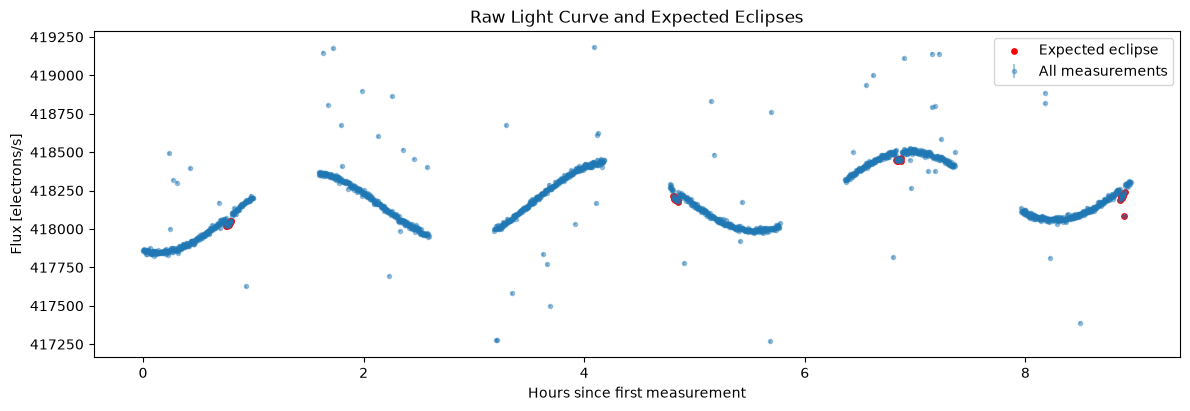

In [245]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lombscargle
from scipy.optimize import curve_fit

# Set to True to save every figure as a 300 dpi PNG.
save = True

time, flux, error = np.loadtxt("data_headers.dat", skiprows=3, unpack=True)

exposure = 13.2 #seconds
period_hst = 95.48 #minutes
t_start = 57531.87312 #days

duration_eclipse = 166.484 / 86400 #days
t_central_first_eclipse = 57531.91792371155 #days
period_eclipse = 2.025026511149096 / 24 #days

# Time from the nearest eclipse center.
# dt lies between -period_eclipse/2 and +period_eclipse/2
# This calculates the signed time from each measurement to its nearest eclipse center:
# Negative: before the center.
# Zero: at the center.
# Positive: after the center.
dt = (time - t_central_first_eclipse + period_eclipse / 2) % period_eclipse - period_eclipse / 2

# Boolean mask. Each entry is True if that measurement falls within the predicted eclipse.
in_eclipse = np.abs(dt) < duration_eclipse / 2

hours = (time - time.min()) * 24

plt.figure(figsize=(12, 4))
plt.errorbar(hours, flux, yerr=error, fmt=".", alpha=0.4, label="All measurements")
plt.scatter(hours[in_eclipse], flux[in_eclipse], color="red", s=15, label="Expected eclipse")
plt.xlabel("Hours since first measurement")
plt.ylabel("Flux [electrons/s]")
plt.legend()
plt.tight_layout()
plt.title("Raw Light Curve and Expected Eclipses")
if save:
    plt.savefig("01_raw_light_curve.png", dpi=300, bbox_inches="tight")
plt.show()

Flagged 59 of 1605 measurements.
Remaining measurements: 1546


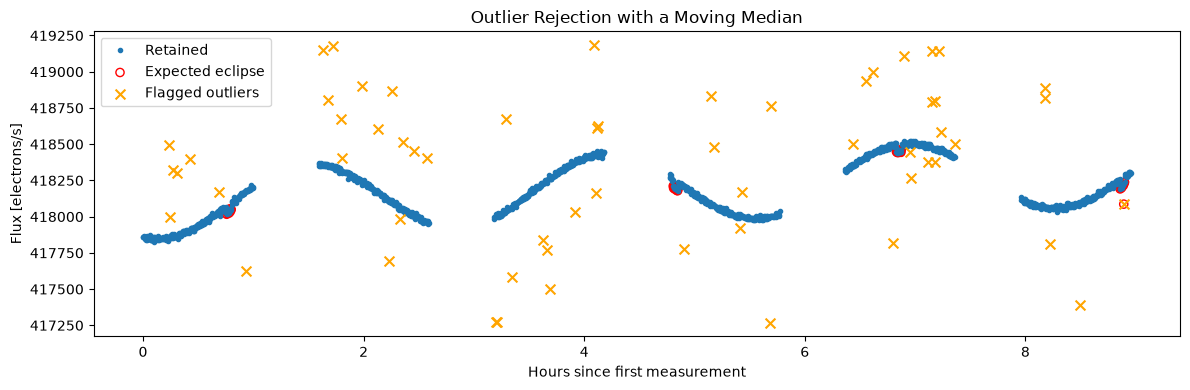

In [246]:
# ------------------------------------------------------------------
# Step 1: Identify and remove likely cosmic-ray outliers
# ------------------------------------------------------------------

# Use measurements within 60 seconds on either side of each point.
# +/-60 s usually includes nine exposures at the 13.2 s cadence.
half_window_seconds = 60
half_window = half_window_seconds / 86400  # days
min_neighbors = 5
sigma_cutoff = 5

local_median = np.full(len(flux), np.nan)

# For point i select measurements within 60 seconds before and after it.
for i in range(len(flux)):
    # Selects measurements close in time.
    nearby = np.abs(time - time[i]) <= half_window

    # Keep eclipse and out-of-eclipse measurements separate.

    # Selects measurements that share the point’s eclipse status.
    same_region = in_eclipse == in_eclipse[i]
    
    #A point becomes a neighbor only if it is both:
    # Within 60 seconds of the selected measurement. In the same eclipse state: both inside, or both outside.
    neighbors = nearby & same_region

    # Require enough points for a useful median.
    if np.sum(neighbors) >= min_neighbors:
        local_median[i] = np.median(flux[neighbors])

# Difference from the local median, in units of measurement error.
deviation = (flux - local_median) / error

# Require a valid median and a large deviation in either direction.
outlier = (
    np.isfinite(local_median)
    & (np.abs(deviation) > sigma_cutoff)
)

keep = ~outlier

# Cleaned arrays for the next step.
time_clean = time[keep]
flux_clean = flux[keep]
error_clean = error[keep]
in_eclipse_clean = in_eclipse[keep]

print(f"Flagged {np.sum(outlier)} of {len(flux)} measurements.")
print(f"Remaining measurements: {np.sum(keep)}")

# Inspect the result.
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hours[keep], flux[keep], ".", color="tab:blue", label="Retained")
ax.scatter(hours[in_eclipse], flux[in_eclipse], facecolors="none", edgecolors="red", s=35, label="Expected eclipse")
ax.scatter(hours[outlier], flux[outlier], color="orange", marker="x", s=50, label="Flagged outliers", zorder=5)
ax.set_xlabel("Hours since first measurement")
ax.set_ylabel("Flux [electrons/s]")
ax.legend()
ax.set_title("Outlier Rejection with a Moving Median")
plt.tight_layout()
if save:
    plt.savefig("02_outlier_rejection.png", dpi=300, bbox_inches="tight")
plt.show()

Elapsed baseline: 8.954 hours
Period search: 26.4 seconds to 17.908 hours
Broad frequency grid: 12206 trials
Strongest broad-grid peaks (period in hours, normalized power):
2.71333 h : 0.9658
4.26381 h : 0.2595
1.01750 h : 0.2300
11.19250 h : 0.0899
1.90511 h : 0.0544
Initial estimate of stellar period: 2.7094 hours


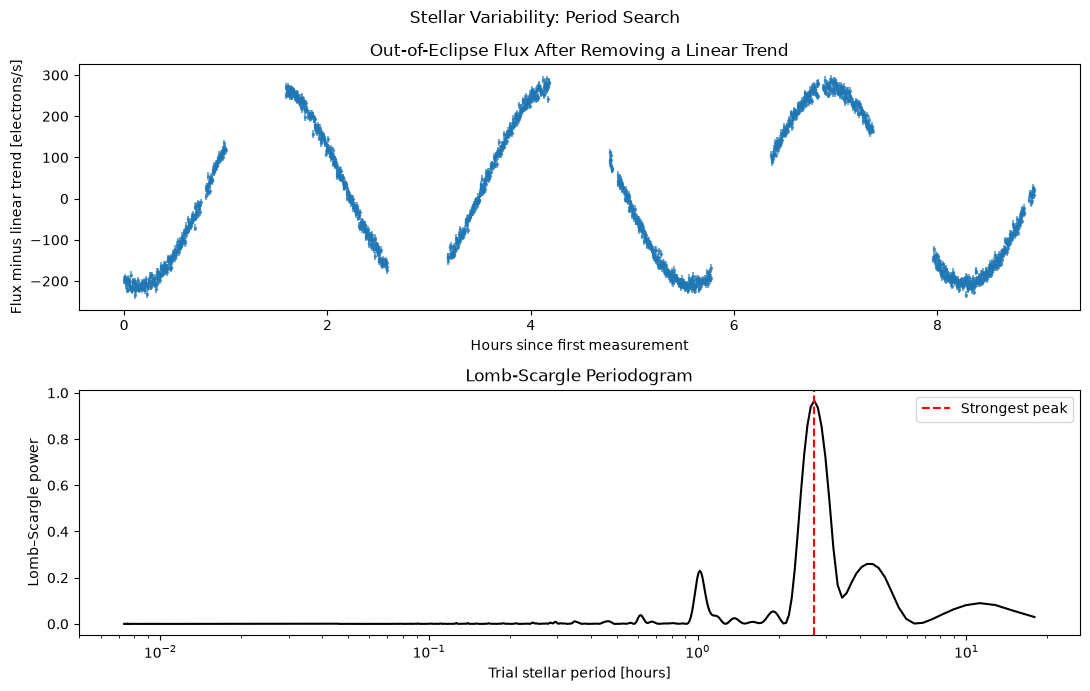

In [247]:
# ------------------------------------------------------------------
# Step 2: Estimate and subtract the changing background
# ------------------------------------------------------------------

# Select data for estimating the background.

# Use all retained out-of-eclipse measurements to fit the background.
background_mask = ~in_eclipse_clean

time_background = time_clean[background_mask]
flux_background = flux_clean[background_mask]
error_background = error_clean[background_mask]

# Center the time values to make fitting easier.
t_pivot = np.median(time_background)
t_background = time_background - t_pivot  # days

# Temporarily remove a linear trend.

# np.polyfit uses weights of 1/error, not 1/error**2.
slope_initial, intercept_initial = np.polyfit(
    t_background,
    flux_background,
    deg=1,
    w=1 / error_background
)

linear_background = (intercept_initial + slope_initial * t_background)
flux_for_periodogram = flux_background - linear_background

# Search for the stellar variation period.

baseline_days = time.max() - time.min()
cadence_days = exposure / 86400  # supplied regular sampling within segments
min_period_days = 2 * cadence_days
max_period_days = 2 * baseline_days

samples_per_peak = 10
frequency_step = 1 / (samples_per_peak * baseline_days)
min_frequency = 1 / max_period_days
max_frequency = 1 / min_period_days
n_frequencies = int(np.ceil((max_frequency - min_frequency) / frequency_step)) + 1
frequencies = np.linspace(min_frequency, max_frequency, n_frequencies)
periods_days = 1 / frequencies
periods_hours = periods_days * 24

# scipy's Lomb-Scargle function expects radians/day, not cycles/day.
angular_frequencies = 2 * np.pi * frequencies

print(f"Elapsed baseline: {baseline_days * 24:.3f} hours")
print(f"Period search: {min_period_days * 86400:.1f} seconds " f"to {max_period_days * 24:.3f} hours")
print(f"Broad frequency grid: {n_frequencies} trials")

# Lomb-Scargle searches sinusoidal variation at the actual observation times, including the observing gaps.
power = lombscargle(
    t_background,
    flux_for_periodogram,
    angular_frequencies,
    precenter=True,
    normalize=True
)
# argmax returns the index of the strongest peak, not its period value.
best_index = np.argmax(power)
if best_index == 0 or best_index == len(frequencies) - 1:
    raise ValueError("Strongest peak is at a search boundary; inspect the range.")

# Zoom in around the strongest peak from the first search
refined_frequencies = np.linspace(frequencies[best_index - 1], frequencies[best_index + 1], 501)
refined_power = lombscargle(
    t_background, 
    flux_for_periodogram, 
    2 * np.pi * refined_frequencies,
    precenter=True, 
    normalize=True
)
period_star_initial = 1 / refined_frequencies[np.argmax(refined_power)]

# Display competing local maxima: HST gaps can create aliases.
from scipy.signal import find_peaks
peak_indices, _ = find_peaks(power)
ranked_peaks = peak_indices[np.argsort(power[peak_indices])[::-1]][:5]
print("Strongest broad-grid peaks (period in hours, normalized power):")
for index in ranked_peaks:
    print(f"{periods_hours[index]:.5f} h : {power[index]:.4f}")

print("Initial estimate of stellar period: "f"{period_star_initial * 24:.4f} hours")

# Plot the temporarily detrended data and periodogram.
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].errorbar(
    (time_background - time.min()) * 24,
    flux_for_periodogram,
    yerr=error_background,
    fmt=".",
    markersize=3,
    alpha=0.6
)
axes[0].set_xlabel("Hours since first measurement")
axes[0].set_ylabel("Flux minus linear trend [electrons/s]")
# Frequencies increase, so their corresponding periods decrease.
# Sort for plotting; a logarithmic axis shows both seconds and hours clearly.
period_order = np.argsort(periods_hours)
axes[1].semilogx(periods_hours[period_order], power[period_order], color="black")
axes[1].axvline(
    period_star_initial * 24,
    color="red",
    linestyle="--",
    label="Strongest peak"
)
axes[1].set_xlabel("Trial stellar period [hours]")
axes[1].set_ylabel("Lomb–Scargle power")
axes[1].legend()
fig.suptitle("Stellar Variability: Period Search")
axes[0].set_title("Out-of-Eclipse Flux After Removing a Linear Trend")
axes[1].set_title("Lomb-Scargle Periodogram")
plt.tight_layout()
if save:
    plt.savefig("03_stellar_period_search.png", dpi=300, bbox_inches="tight")
plt.show()

In [248]:
# Background: straight line + sinusoid.
# t and P are in days.
def background_model(t, a, b, A, P, phi):
    return a + b*t + A*np.sin(2*np.pi*t/P + phi)

# Estimate starting parameters at the period found in Step 2.
# Sine and cosine together let us estimate amplitude and phase.
angle = 2 * np.pi * t_background / period_star_initial

X = np.column_stack([
    np.ones(len(t_background)),
    t_background,
    np.sin(angle),
    np.cos(angle)
])

a0, b0, s0, c0 = np.linalg.lstsq(
    X / error_background[:, None],
    flux_background / error_background,
    rcond=None
)[0]

initial_parameters = [
    a0,
    b0,
    np.hypot(s0, c0), # amplitude
    period_star_initial,
    np.arctan2(c0, s0) # phase
]

# Fit all five background parameters together.
# curve_fit adjusts the baseline, slope, amplitude, period, and phase to minimize chi2.
parameters, covariance = curve_fit(
    background_model,
    t_background,
    flux_background,
    p0=initial_parameters,
    sigma=error_background,
    absolute_sigma=True,
    bounds=(
    [-np.inf, -np.inf, 0, min_period_days, -np.inf],
    [ np.inf,  np.inf, np.inf, max_period_days, np.inf]
    ),
    maxfev=20000
)

# Predict the background at every retained measurement.
background = background_model(time_clean - t_pivot, *parameters)

# Outside eclipses: approximately zero.
# Inside eclipses: negative because some light is missing.
flux_detrended = flux_clean - background

print(f"Fitted stellar period: {parameters[3] * 24:.4f} hours")

Fitted stellar period: 2.7156 hours


In [249]:
# ------------------------------------------------------------------
# Step 3: Measure the eclipse depth
# ------------------------------------------------------------------

# Use all retained in-eclipse measurements.
depth_mask = in_eclipse_clean

# The missing flux is the negative of the detrended flux.
eclipse_residuals = flux_detrended[depth_mask]
eclipse_errors = error_clean[depth_mask]

weights = 1 / eclipse_errors**2

# A dip has negative residuals, so negate their weighted average.
depth = -np.sum(weights * eclipse_residuals) / np.sum(weights)

depth_error = 1 / np.sqrt(np.sum(weights))

print(f"Measurements used: {np.sum(depth_mask)}")
print(f"Eclipse depth: {depth:.2f} ± {depth_error:.2f} electrons/s")

Measurements used: 50
Eclipse depth: 50.42 ± 1.25 electrons/s


In [250]:
# ------------------------------------------------------------------
# Step 4: Propagate background uncertainty using MCMC.
# ------------------------------------------------------------------

def full_model(t, a, b, A, P, phi, d):
    background_flux = background_model(t, a, b, A, P, phi)
    return background_flux - d * eclipse_mcmc

def log_posterior(theta):
    # Reject parameters outside the prior bounds.
    if np.any(theta <= lower) or np.any(theta >= upper):
        return -np.inf

    residual = (f_mcmc - full_model(t_mcmc, *theta)) / e_mcmc

    return -0.5 * np.sum(residual**2)

# Fit every retained measurement, both inside and outside eclipses.
mcmc_mask = np.ones(len(time_clean), dtype=bool)

t_mcmc = time_clean[mcmc_mask] - t_pivot
f_mcmc = flux_clean[mcmc_mask]
e_mcmc = error_clean[mcmc_mask]

# 1 inside an eclipse, 0 outside.
# Subtracts the eclipse depth only during eclipses.
eclipse_mcmc = in_eclipse_clean[mcmc_mask].astype(float)

# Broad uniform prior bounds.
# Order: baseline, slope, amplitude, period, phase, depth.
# Period is in days; phase is in radians.
lower = np.array([0, -1e6, 0, min_period_days, parameters[4] - np.pi, -1e4])
upper = np.array([1e6, 1e6, 1e5, max_period_days, parameters[4] + np.pi, 1e4])

initial_joint_parameters = list(parameters) + [depth]

# Find a good starting point for all six parameters.
start, joint_cov = curve_fit(
    full_model,
    t_mcmc,
    f_mcmc,
    p0 = initial_joint_parameters,
    sigma=e_mcmc,
    absolute_sigma=True,
    bounds=(lower, upper),
    maxfev=20000
)

In [251]:
rng = np.random.default_rng(42)

n_chains = 4
n_steps = 25000
burn_in = 5000
n_parameters = len(start)

# Use the initial fit's approximate parameter uncertainties as jump sizes.
# The diagonal of the covariance matrix contains the parameter variances.
jump_sizes = np.sqrt(np.diag(joint_cov))

if np.any(~np.isfinite(jump_sizes)) or np.any(jump_sizes <= 0):
    raise ValueError("Jump sizes must be finite and positive.")

# Adjust this multiplier if proposals are too large or too small.
proposal_scale = 2.4 / np.sqrt(n_parameters)

# Store [chain, step, parameter].
chains = np.empty((n_chains, n_steps, n_parameters))

for c in range(n_chains):

    # Start each chain at a different point near the joint best fit.
    current = (start + 3 * jump_sizes * rng.normal(size=n_parameters))
    current_logp = log_posterior(current)

    if not np.isfinite(current_logp):
        raise ValueError("Starting point has an invalid log posterior.")

    accepted = 0

    for j in range(n_steps):

        # Propose independent random changes to all six parameters.
        trial = (current + proposal_scale * jump_sizes * rng.normal(size=n_parameters))
        trial_logp = log_posterior(trial)

        # Accept higher-posterior proposals automatically.
        # Sometimes accept lower-posterior proposals as well.
        if np.log(rng.random()) < trial_logp - current_logp:
            current = trial
            current_logp = trial_logp
            accepted += 1

        # If rejected, current stays unchanged and is recorded again.
        chains[c, j] = current

    print(f"Chain {c + 1}: " f"acceptance = {accepted / n_steps:.1%}")

# Discard the initial burn-in steps from every chain.
posterior = chains[:, burn_in:, :]

Chain 1: acceptance = 26.0%
Chain 2: acceptance = 26.4%
Chain 3: acceptance = 25.9%
Chain 4: acceptance = 26.5%


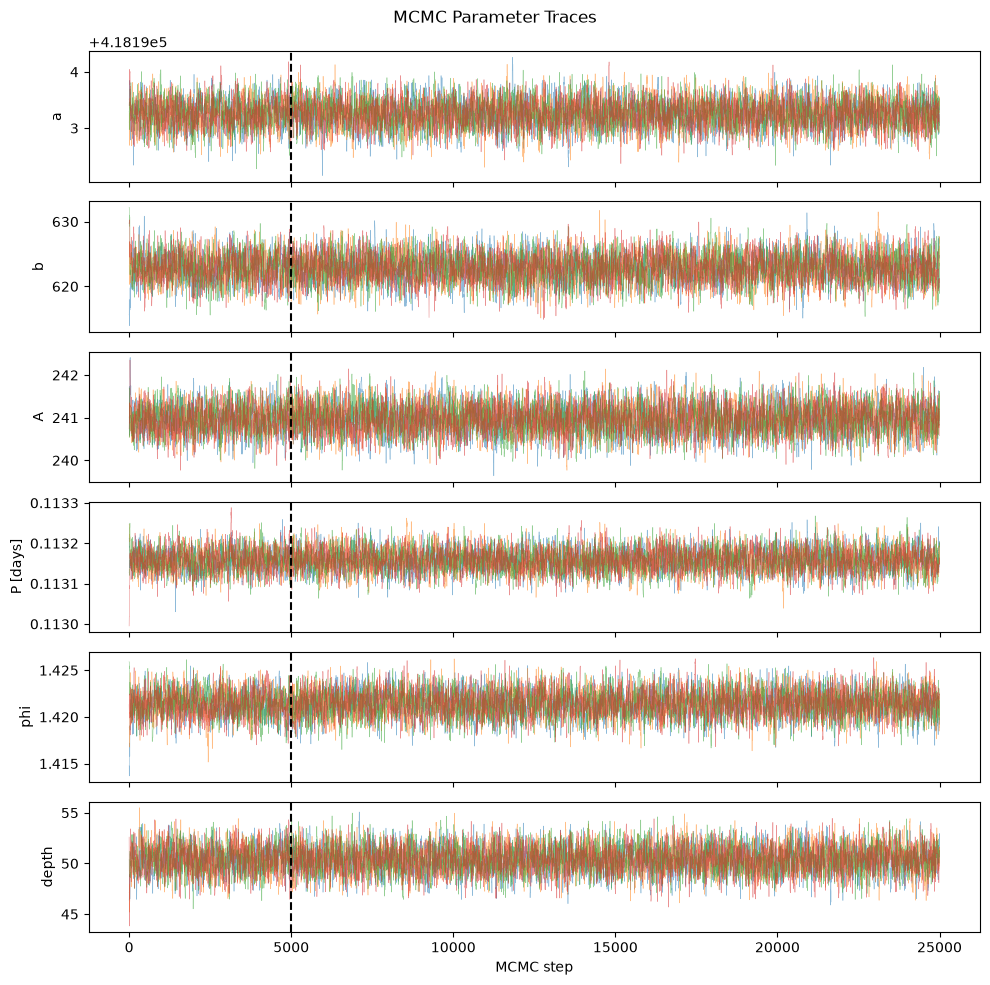

a: split R-hat = 1.0009
b: split R-hat = 1.0002
A: split R-hat = 1.0008
P [days]: split R-hat = 1.0005
phi: split R-hat = 1.0011
depth: split R-hat = 1.0015


In [252]:
parameter_names = ["a", "b", "A", "P [days]", "phi", "depth"]

fig, axes = plt.subplots(6, 1, figsize=(10, 10), sharex=True)

for k, ax in enumerate(axes):
    for c in range(n_chains):
        ax.plot(
            chains[c, :, k],
            alpha=0.5,
            linewidth=0.4
        )

    ax.axvline(burn_in, color="black", linestyle="--")
    ax.set_ylabel(parameter_names[k])

axes[-1].set_xlabel("MCMC step")
fig.suptitle("MCMC Parameter Traces")
plt.tight_layout()
if save:
    plt.savefig("04_mcmc_parameter_traces.png", dpi=300, bbox_inches="tight")
plt.show()

# Basic split R-hat: compares variation within and between chains.
half = posterior.shape[1] // 2

split_chains = np.concatenate([
    posterior[:, :half, :],
    posterior[:, -half:, :]
], axis=0)

within = np.mean(np.var(split_chains, axis=1, ddof=1), axis=0)
between = half * np.var(np.mean(split_chains, axis=1), axis=0, ddof=1)

rhat = np.sqrt(((half - 1) / half * within + between / half) / within)

for name, value in zip(parameter_names, rhat):
    print(f"{name}: split R-hat = {value:.4f}")

MCMC depth: 50.41 +1.25 / -1.26 electrons/s
Posterior standard deviation: 1.26 electrons/s


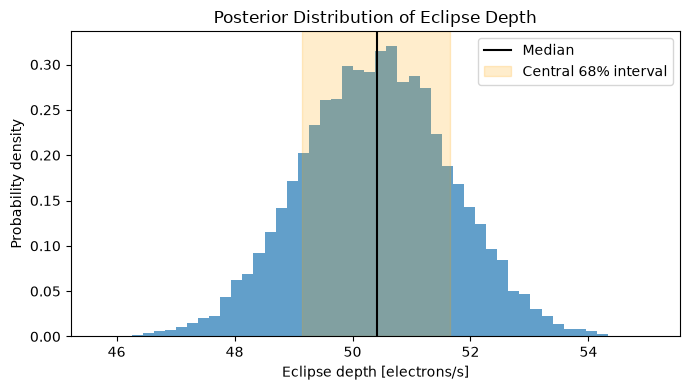

In [253]:
depth_samples = posterior[:, :, 5].reshape(-1)

q16, q50, q84 = np.percentile(depth_samples, [16, 50, 84])

depth_mcmc = q50
error_lower = q50 - q16
error_upper = q84 - q50

print(f"MCMC depth: {depth_mcmc:.2f} " f"+{error_upper:.2f} / -{error_lower:.2f} electrons/s")
print("Posterior standard deviation: " f"{np.std(depth_samples, ddof=1):.2f} electrons/s")

plt.figure(figsize=(7, 4))
plt.hist(depth_samples, bins=50, density=True, alpha=0.7)
plt.axvline(q50, color="black", label="Median")
plt.axvspan(q16, q84, color="orange", alpha=0.2,
            label="Central 68% interval")
plt.xlabel("Eclipse depth [electrons/s]")
plt.ylabel("Probability density")
plt.title("Posterior Distribution of Eclipse Depth")
plt.legend()
plt.tight_layout()
if save:
    plt.savefig("05_eclipse_depth_posterior.png", dpi=300, bbox_inches="tight")
plt.show()

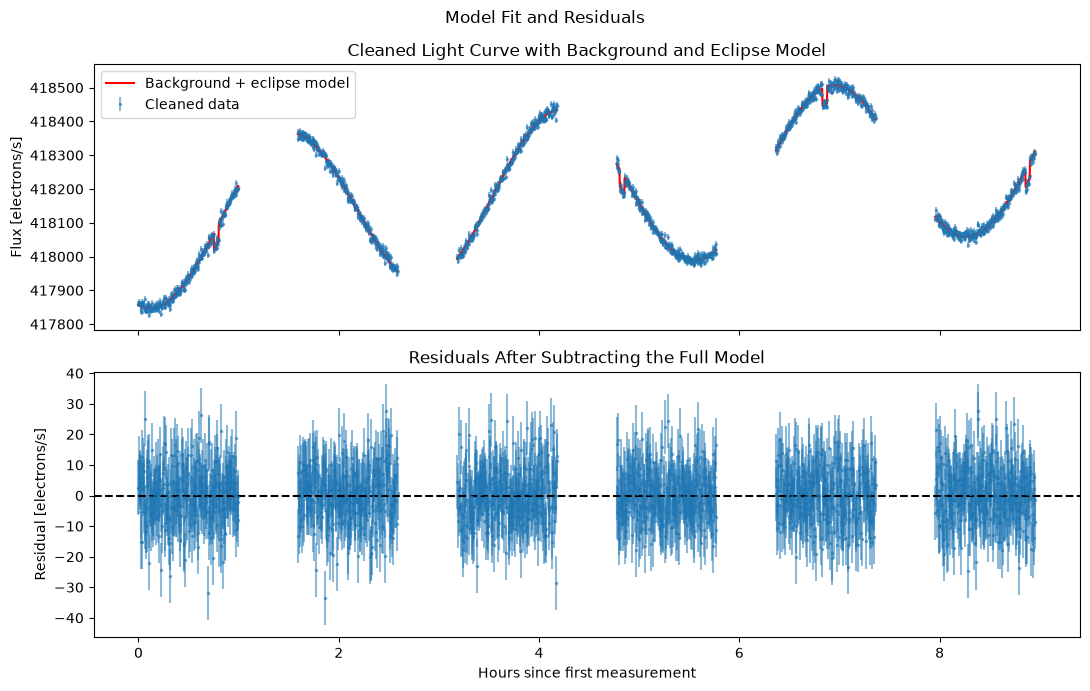

In [254]:
# ------------------------------------------------------------------
# Step 5: Model and residuals
# ------------------------------------------------------------------

# Model and residuals

# One representative parameter set from the MCMC.
theta_plot = np.median(posterior.reshape(-1, 6), axis=0)

time_diag = time_clean[mcmc_mask]
hours_diag = (time_diag - time.min()) * 24

model_diag = full_model(t_mcmc, *theta_plot)
residuals = f_mcmc - model_diag

# Normalized residuals, used later.
z = residuals / e_mcmc

# Identify separate observing segments.
# A gap longer than five exposures starts a new segment.
segment = np.r_[0,np.cumsum(np.diff(time_diag) * 86400 > 5 * exposure)]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Top panel: cleaned measurements and fitted model.
axes[0].errorbar(
    hours_diag,
    f_mcmc,
    yerr=e_mcmc,
    fmt=".",
    markersize=3,
    alpha=0.5,
    label="Cleaned data"
)

# Plot separately within each segment to avoid joining across gaps.
for s in np.unique(segment):
    select = segment == s

    axes[0].plot(
        hours_diag[select],
        model_diag[select],
        color="red",
        label="Background + eclipse model" if s == 0 else None
    )

axes[0].set_ylabel("Flux [electrons/s]")
axes[0].legend()

# Bottom panel: what remains after subtracting the full model.
axes[1].errorbar(
    hours_diag,
    residuals,
    yerr=e_mcmc,
    fmt=".",
    markersize=3,
    alpha=0.5
)

axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Hours since first measurement")
axes[1].set_ylabel("Residual [electrons/s]")
fig.suptitle("Model Fit and Residuals")
axes[0].set_title("Cleaned Light Curve with Background and Eclipse Model")
axes[1].set_title("Residuals After Subtracting the Full Model")
plt.tight_layout()
if save:
    plt.savefig("06_model_and_residuals.png", dpi=300, bbox_inches="tight")
plt.show()

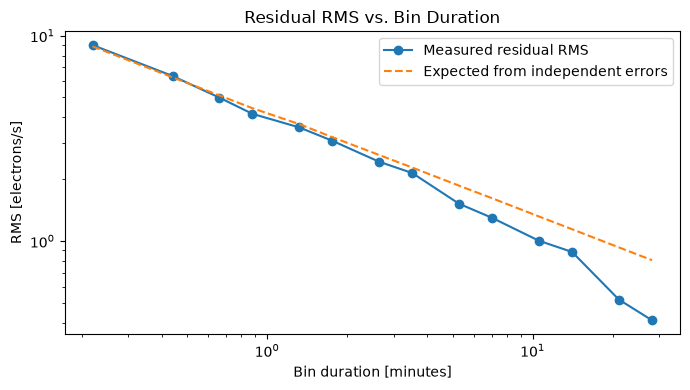

In [255]:
# Residual RMS versus bin size

# Nominal number of exposure slots per bin.
bin_sizes = np.array([1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128])

bin_minutes = []
rms_measured = []
rms_white = []

for N in bin_sizes:

    bin_means = []
    bin_variances = []

    for s in np.unique(segment):

        select = segment == s
        ts = time_diag[select]
        rs = residuals[select]
        es = e_mcmc[select]

        # Assign each measurement to its original cadence slot.
        # Removed measurements therefore leave empty slots.
        slot = np.rint((ts - ts[0]) * 86400 / exposure).astype(int)

        bin_id = slot // N

        # Exclude the final incomplete time bin.
        n_complete_bins = (slot[-1] + 1) // N

        for b in range(n_complete_bins):

            inside = bin_id == b

            # Require at least 80% of the expected measurements.
            if np.sum(inside) < np.ceil(0.8 * N):
                continue

            w = 1 / es[inside]**2

            # Weighted mean residual in this bin.
            mean_residual = (np.sum(w * rs[inside]) / np.sum(w))

            # Expected variance of that mean for independent errors.
            variance_of_mean = 1 / np.sum(w)

            bin_means.append(mean_residual)
            bin_variances.append(variance_of_mean)

    # Avoid estimating RMS from only a handful of bins.
    if len(bin_means) >= 10:

        bin_minutes.append(N * exposure / 60)

        rms_measured.append(np.sqrt(np.mean(np.array(bin_means)**2)))

        rms_white.append(np.sqrt(np.mean(bin_variances)))

plt.figure(figsize=(7, 4))
plt.loglog(
    bin_minutes,
    rms_measured,
    "o-",
    label="Measured residual RMS"
)
plt.loglog(
    bin_minutes,
    rms_white,
    "--",
    label="Expected from independent errors"
)
plt.xlabel("Bin duration [minutes]")
plt.ylabel("RMS [electrons/s]")
plt.title("Residual RMS vs. Bin Duration")
plt.legend()
plt.tight_layout()
if save:
    plt.savefig("07_residual_rms_vs_bin_duration.png", dpi=300, bbox_inches="tight")
plt.show()

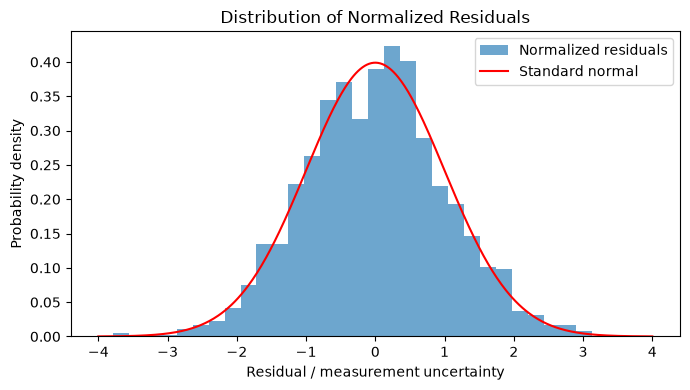

Mean normalized residual: -0.000
Normalized residual standard deviation: 1.015
Approximate reduced chi-squared: 1.034


In [256]:
# Histogram of normalized residuals

plt.figure(figsize=(7, 4))
plt.hist(
    z,
    bins=30,
    density=True,
    alpha=0.65,
    label="Normalized residuals"
)

# Standard normal distribution: mean 0, standard deviation 1.
x = np.linspace(min(-4, z.min()), max(4, z.max()),500)

standard_normal = (np.exp(-x**2 / 2) / np.sqrt(2 * np.pi))

plt.plot(
    x,
    standard_normal,
    color="red",
    label="Standard normal"
)
plt.xlabel("Residual / measurement uncertainty")
plt.ylabel("Probability density")
plt.legend()
plt.title("Distribution of Normalized Residuals")
plt.tight_layout()
if save:
    plt.savefig("08_normalized_residual_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

# Numerical checks.
n_parameters = 6

reduced_chi_squared = (np.sum(z**2) / (len(z) - n_parameters))

print(f"Mean normalized residual: {np.mean(z):.3f}")
print("Normalized residual standard deviation: " f"{np.std(z, ddof=1):.3f}")
print(f"Approximate reduced chi-squared: {reduced_chi_squared:.3f}")